In [47]:
#imports

import pandas as pd
import matplotlib.pyplot as plt

In [48]:

df = pd.read_csv(
    "data/Perovskite_database_content_all_data.csv",
    low_memory=False, 
    encoding="cp1252",
)

print(df.shape)


(42851, 410)


In [49]:
display(df.head())

,Ref_ID,Ref_ID_temp,Ref_name_of_person_entering_the_data,Ref_data_entered_by_author,Ref_DOI_number,Ref_lead_author,Ref_publication_date,Ref_journal,Ref_part_of_initial_dataset,Ref_original_filename_data_upload,...,Outdoor_PCE_Tse80,Outdoor_PCE_after_1000_h,Outdoor_power_generated,Outdoor_link_raw_data_for_outdoor_trace,Outdoor_detaild_weather_data_available,Outdoor_link_detailed_weather_data,Outdoor_spectral_data_available,Outdoor_link_spectral_data,Outdoor_irradiance_measured,Outdoor_link_irradiance_data
0,1,1,Adam Hultqvist,False,10.1021/jp5126624,Sabba et al.,6/1/2015,The Journal of Physical Chemistry C,True,Historic dataset on 2020 11 22_v7.xlsx,...,NaN,NaN,NaN,NaN,False,NaN,False,NaN,False,NaN
1,2,2,Adam Hultqvist,False,10.1021/jp5126624,Sabba et al.,6/1/2015,The Journal of Physical Chemistry C,True,Historic dataset on 2020 11 22_v7.xlsx,...,NaN,NaN,NaN,NaN,False,NaN,False,NaN,False,NaN
2,3,3,Adam Hultqvist,False,10.1021/jp5126624,Sabba et al.,6/1/2015,The Journal of Physical Chemistry C,True,Historic dataset on 2020 11 22_v7.xlsx,...,NaN,NaN,NaN,NaN,False,NaN,False,NaN,False,NaN
3,4,4,Adam Hultqvist,False,10.1021/jp5126624,Sabba et al.,6/1/2015,The Journal of Physical Chemistry C,True,Historic dataset on 2020 11 22_v7.xlsx,...,NaN,NaN,NaN,NaN,False,NaN,False,NaN,False,NaN
4,5,5,Adam Hultqvist,False,10.1021/jp5126624,Sabba et al.,6/1/2015,The Journal of Physical Chemistry C,True,Historic dataset on 2020 11 22_v7.xlsx,...,NaN,NaN,NaN,NaN,False,NaN,False,NaN,False,NaN


In [50]:
#Sorting columns from most missing to least missing values

missing = df.isnull().sum()
display(
    missing[missing > 0].sort_values(ascending=False)
)

Cell_flexible_min_bending_radius        42851
Outdoor_PCE_Te80                        42851
Outdoor_PCE_Tse80                       42851
Substrate_surface_roughness_rms         42851
Stability_lifetime_energy_yield         42851
                                        ...  
Perovskite_composition_b_ions              44
Ref_lead_author                            39
Ref_name_of_person_entering_the_data       39
Perovskite_composition_short_form          32
Perovskite_composition_long_form           32
Length: 355, dtype: int64

In [51]:
# Remove columns with all missing values

df_clean = df.dropna(axis=1, how="all")
print("Original dimensions:", df.shape)
print("New dimensions:", df_clean.shape)
print("Columns removed:", df.shape[1]-df_clean.shape[1])

Original dimensions: (42851, 410)
New dimensions: (42851, 383)
Columns removed: 27


In [52]:
#search for relevant columns to assess which we want to keep

keywords = [
    "Perovskite_composition",
    "bandgap",
    "band_gap",
    "JV_",
    "ETL",
    "HTL",
    "Substrate",
    "Backcontact",
    "Cell_architecture"
]
relevant_col = [
    col for col in df_clean.columns
    if any(word.lower() in col.lower() for word in keywords)
]
print(relevant_col)

['Cell_number_of_cells_per_substrate', 'Cell_architecture', 'Module_JV_data_recalculated_per_cell', 'Substrate_stack_sequence', 'Substrate_thickness', 'Substrate_area', 'Substrate_supplier', 'Substrate_brand_name', 'Substrate_deposition_procedure', 'Substrate_etching_procedure', 'Substrate_cleaning_procedure', 'ETL_stack_sequence', 'ETL_thickness', 'ETL_additives_compounds', 'ETL_additives_concentrations', 'ETL_deposition_procedure', 'ETL_deposition_aggregation_state_of_reactants', 'ETL_deposition_synthesis_atmosphere', 'ETL_deposition_synthesis_atmosphere_pressure_total', 'ETL_deposition_synthesis_atmosphere_pressure_partial', 'ETL_deposition_synthesis_atmosphere_relative_humidity', 'ETL_deposition_solvents', 'ETL_deposition_solvents_mixing_ratios', 'ETL_deposition_solvents_supplier', 'ETL_deposition_solvents_purity', 'ETL_deposition_reaction_solutions_compounds', 'ETL_deposition_reaction_solutions_compounds_supplier', 'ETL_deposition_reaction_solutions_compounds_purity', 'ETL_deposit

In [53]:
#choosing columns to keep and renaming them to shorter, interpretablenames

keep = {
    "Perovskite_composition_a_ions": "A_ions", "Perovskite_composition_a_ions_coefficients": "A_coef",
    "Perovskite_composition_b_ions": "B_ions", "Perovskite_composition_b_ions_coefficients": "B_coef",
    "Perovskite_composition_c_ions": "X_ions", "Perovskite_composition_c_ions_coefficients": "X_coef",
    "Perovskite_band_gap": "Eg", "Perovskite_band_gap_estimation_basis": "Eg_basis",
    "JV_default_PCE": "PCE", "JV_default_Voc": "Voc", "JV_default_Jsc": "Jsc", "JV_default_FF": "FF",
    "ETL_stack_sequence": "ETL", "HTL_stack_sequence": "HTL",
    "Substrate_stack_sequence": "Substrate", "Backcontact_stack_sequence": "Backcontact",
    "Cell_architecture": "Architecture", "Cell_area_measured": "Area",
    "Perovskite_dimension_3D": "is_3D", "Perovskite_composition_perovskite_ABC3_structure": "is_ABX3",
    "Perovskite_single_crystal": "single_crystal", "Module": "module",
}
d = df_clean[list(keep)].rename(columns=keep)

In [54]:
print(d.columns)
print(d.shape)

Index(['A_ions', 'A_coef', 'B_ions', 'B_coef', 'X_ions', 'X_coef', 'Eg',
       'Eg_basis', 'PCE', 'Voc', 'Jsc', 'FF', 'ETL', 'HTL', 'Substrate',
       'Backcontact', 'Architecture', 'Area', 'is_3D', 'is_ABX3',
       'single_crystal', 'module'],
      dtype='str')
(42851, 22)


In [55]:
#keeping only 3D ABX3 perovskites, excluding single crystals and modules, and keeping only nip and pin architectures
#In the dataset a | separates layers, so a | in the composition columns means more than one perovskite layer

d = d[d.is_3D & d.is_ABX3 & ~d.single_crystal & ~d.module]
d = d[d.Architecture.isin(["nip", "pin"])]

comp_cols = ["A_ions", "A_coef", "B_ions", "B_coef", "X_ions", "X_coef"]
d = d.dropna(subset=comp_cols)
d = d[~d[comp_cols].apply(lambda c: c.str.contains(r"\|")).any(axis=1)]

In [56]:
#keeping the same elements as in the paper, comment out if more desired

ALLOWED = {"A": {"Cs","FA","MA"}, "B": {"Pb","Sn"}, "X": {"I","Br","Cl"}}
split = lambda s: [t.strip() for t in str(s).split(";")]
for site in "ABX":
    d = d[d[f"{site}_ions"].apply(lambda s: set(split(s)) <= ALLOWED[site])]

In [57]:
#turn the composition into numeric descriptions (featurisation)

def split(text):
    """'Cs; FA; MA'  ->  ['Cs', 'FA', 'MA']"""
    pieces = text.split(";")             # ['Cs', ' FA', ' MA']  (note the spaces)
    return [p.strip() for p in pieces]   # .strip() removes the spaces


def parse_site(ions_text, coefs_text, total):
    """
    Turn one site into a dictionary of element -> amount.
    e.g. ('Br; I', '0.45; 2.55', 3)  ->  {'Br': 0.45, 'I': 2.55}
    Returns None if the entry can't be used.
    """
    ions = split(ions_text)
    coefs = split(coefs_text)

    # Step 2: same number of ions and coefficients?
    if len(ions) != len(coefs):
        return None

    # Step 3: convert text to numbers. If any piece isn't a number (e.g. 'x'), give up.
    numbers = []
    for c in coefs:
        try:
            numbers.append(float(c))
        except ValueError:
            return None

    # Step 4: normalise so the site adds up to `total`
    site_sum = sum(numbers)
    if site_sum <= 0:
        return None
    result = {}
    for ion, n in zip(ions, numbers):
        result[ion] = n / site_sum * total
    return result


ELEMENTS = ["Cs", "FA", "MA", "Pb", "Sn", "I", "Br", "Cl"]

rows = []          # one dictionary per device
keep_index = []    # which rows of d were parsed successfully

for idx, row in d.iterrows():
    a = parse_site(str(row["A_ions"]), str(row["A_coef"]), 1)
    b = parse_site(str(row["B_ions"]), str(row["B_coef"]), 1)
    x = parse_site(str(row["X_ions"]), str(row["X_coef"]), 3)

    if a is None or b is None or x is None:
        continue   # skip this device if any site failed

    combined = {**a, **b, **x}   # merge the three dictionaries into one
    # make sure every element has a value, using 0 if it isn't present
    rows.append({el: round(combined.get(el, 0), 3) for el in ELEMENTS})
    keep_index.append(idx)

comp = ["Cs","FA","MA","Pb","Sn","I","Br","Cl"]
stoich = pd.DataFrame(rows, index=keep_index)
d = d.loc[keep_index].join(stoich)


In [58]:
d["Eg"] = pd.to_numeric(d.Eg, errors="coerce")   # turns '1.6 | 1.68' or '1.8-2.3' into NaN
d.loc[d.FF > 1, "FF"] /= 100                      # some fill factors are entered as %

In [59]:
#from Hussain paper, creating subset 1 for bandgap model

bg = d.dropna(subset=["Eg"]).query("1.1 <= Eg <= 3.2")
bg_data = bg.groupby(S, as_index=False).agg(Eg=("Eg","median"), n=("Eg","size"))   # 588 rows



In [60]:
#subset 2 for PCE model, removing outliers and keeping only the most frequent layers

p = d.dropna(subset=["PCE","Voc","Jsc","FF","Eg","Area"])
p = p[p.PCE.between(0.5,27) & p.Voc.between(0.2,1.5) & p.Jsc.between(1,30)
      & p.FF.between(0.2,0.9) & p.Area.between(0.01,2)]

# consistency check (paper's eqn 2): PCE ≈ Jsc·Voc·FF at 100 mW/cm²
p = p[(p.Jsc*p.Voc*p.FF - p.PCE).abs() / p.PCE < 0.10]

# keep only the most frequent layers
for col, k in {"ETL":6, "HTL":6, "Substrate":2, "Backcontact":3}.items():
    p = p[p[col].isin(p[col].value_counts().nlargest(k).index)]

# one row per device recipe/composition
features = comp + ["Architecture","ETL","HTL","Substrate","Backcontact"]
pce_data = p.groupby(features, as_index=False)[["PCE","Voc","Jsc","FF","Eg","Area"]].mean()  # 635 rows

In [61]:
#preparing data for the model - one hot encoding the categorical features and separating the target variable

X = pd.get_dummies(pce_data[comp + ["Eg","Area","Architecture","ETL","HTL","Substrate","Backcontact"]],
                   columns=["Architecture","ETL","HTL","Substrate","Backcontact"], dtype=int)
y = pce_data["PCE"]

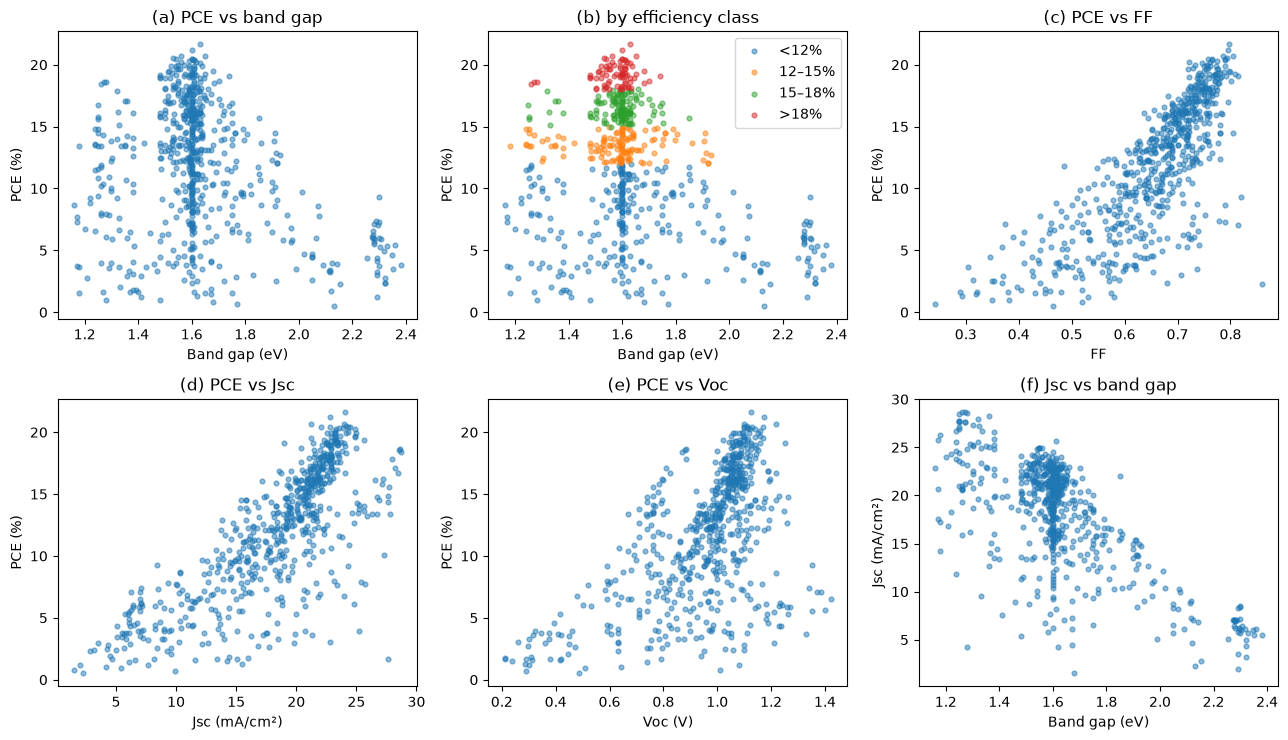

In [62]:
#plotting data for easier visualisation of the relationships between PCE and other features

fig, ax = plt.subplots(2, 3, figsize=(13, 7.5))
ax = ax.ravel()
kw = dict(s=12, alpha=0.5)            # shared styling, reused in every panel

# (a) PCE vs band gap
ax[0].scatter(pce_data["Eg"], pce_data["PCE"], **kw)
ax[0].set(xlabel="Band gap (eV)", ylabel="PCE (%)", title="(a) PCE vs band gap")

# (b) same, coloured by efficiency class
classes = pd.cut(pce_data["PCE"], bins=[0, 12, 15, 18, 30],
                 labels=["<12%", "12–15%", "15–18%", ">18%"])
for label in classes.cat.categories:
    subset = pce_data[classes == label]
    ax[1].scatter(subset["Eg"], subset["PCE"], label=label, **kw)
ax[1].legend()
ax[1].set(xlabel="Band gap (eV)", ylabel="PCE (%)", title="(b) by efficiency class")

# (c)–(f)
ax[2].scatter(pce_data["FF"],  pce_data["PCE"], **kw); ax[2].set(xlabel="FF",              ylabel="PCE (%)", title="(c) PCE vs FF")
ax[3].scatter(pce_data["Jsc"], pce_data["PCE"], **kw); ax[3].set(xlabel="Jsc (mA/cm²)",    ylabel="PCE (%)", title="(d) PCE vs Jsc")
ax[4].scatter(pce_data["Voc"], pce_data["PCE"], **kw); ax[4].set(xlabel="Voc (V)",         ylabel="PCE (%)", title="(e) PCE vs Voc")
ax[5].scatter(pce_data["Eg"],  pce_data["Jsc"], **kw); ax[5].set(xlabel="Band gap (eV)",   ylabel="Jsc (mA/cm²)", title="(f) Jsc vs band gap")

fig.tight_layout()                    # stops labels overlapping
plt.show()

In [63]:
pce_data.to_csv("data/pce_data_clean.csv", index=False)
bg_data.to_csv("data/bandgap_data_clean.csv", index=False)
print("Saved:", pce_data.shape, bg_data.shape)   # (635, 19) (588, 10)

Saved: (635, 19) (588, 10)
